# Difference-in-Differences: a minimal simulation

**Setup.** Two groups (treated and control), two periods (before and after). A policy hits only the treated group in the second period.

Outcome for unit $i$ in group $g$ at time $t$:

$$y_{it} = \alpha + \beta\,\text{Treated}_i + \gamma\,\text{Post}_t + \delta\,(\text{Treated}_i \times \text{Post}_t) + \varepsilon_{it}$$

- $\beta$: permanent level difference between the groups
- $\gamma$: common time trend (affects both groups)
- $\delta$: the **treatment effect** we want

The DiD estimator is

$$\hat\delta = (\bar y_{T,\text{post}} - \bar y_{T,\text{pre}}) - (\bar y_{C,\text{post}} - \bar y_{C,\text{pre}})$$

The control group's change is our estimate of what would have happened to the treated group without the policy (the *parallel trends* assumption).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

rng = np.random.default_rng(42)

## 1. Simulate the data

In [2]:
alpha, beta, gamma, delta = 10.0, 3.0, 2.0, 1.5   # true parameters
n = 500                                           # units per group
sigma = 2.0

rows = []
for treated in (0, 1):
    for post in (0, 1):
        y = (alpha + beta * treated + gamma * post
             + delta * treated * post + rng.normal(0, sigma, n))
        rows.append(pd.DataFrame({"y": y, "treated": treated, "post": post}))
df = pd.concat(rows, ignore_index=True)

means = df.pivot_table(index="treated", columns="post", values="y", aggfunc="mean")
means.index = ["Control", "Treated"]
means.columns = ["Pre", "Post"]
means

,Pre,Post
Control,9.973748,11.910686
Treated,12.992154,16.182333


## 2. DiD by hand: difference of the differences

In [3]:
change = means["Post"] - means["Pre"]
did = change["Treated"] - change["Control"]
print(change.round(3).to_string())
print(f"\nDiD estimate: {did:.3f}   (true effect: {delta})")

Control    1.937
Treated    3.190

DiD estimate: 1.253   (true effect: 1.5)


A naive before/after comparison for the treated group alone mixes the effect with the common trend $\gamma$; a naive post-period comparison of the groups mixes it with the level gap $\beta$.

In [4]:
print(f"Treated before/after only : {change['Treated']:.3f}  (= gamma + delta = {gamma + delta})")
print(f"Post-period groups only    : {means['Post']['Treated'] - means['Post']['Control']:.3f}  (= beta + delta = {beta + delta})")

Treated before/after only : 3.190  (= gamma + delta = 3.5)
Post-period groups only    : 4.272  (= beta + delta = 4.5)


## 3. DiD by regression

The coefficient on the interaction is the same estimator, and comes with a standard error.

In [5]:
model = smf.ols("y ~ treated * post", data=df).fit(cov_type="HC1")
print(model.summary().tables[1])

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        9.9737      0.086    116.164      0.000       9.805      10.142
treated          3.0184      0.125     24.077      0.000       2.773       3.264
post             1.9369      0.125     15.474      0.000       1.692       2.182
treated:post     1.2532      0.179      7.000      0.000       0.902       1.604


## 4. Picture

The dashed line is the treated group's *counterfactual*: its pre-period level plus the control group's change. The gap between it and the actual post-period mean is $\hat\delta$.

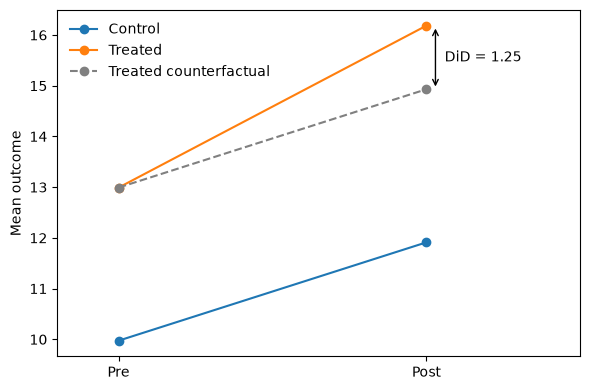

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
x = [0, 1]
ax.plot(x, means.loc["Control"], "o-", label="Control")
ax.plot(x, means.loc["Treated"], "o-", label="Treated")
cf = [means.loc["Treated", "Pre"], means.loc["Treated", "Pre"] + change["Control"]]
ax.plot(x, cf, "o--", color="gray", label="Treated counterfactual")
ax.annotate("", xy=(1.03, means.loc["Treated", "Post"]), xytext=(1.03, cf[1]),
            arrowprops=dict(arrowstyle="<->"))
ax.text(1.06, (cf[1] + means.loc["Treated", "Post"]) / 2, f"DiD = {did:.2f}", va="center")
ax.set_xticks(x, ["Pre", "Post"])
ax.set_xlim(-0.2, 1.5)
ax.set_ylabel("Mean outcome")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 5. Repeated sampling

Is the estimator unbiased? Repeat the experiment many times.

mean = 1.507, sd = 0.280


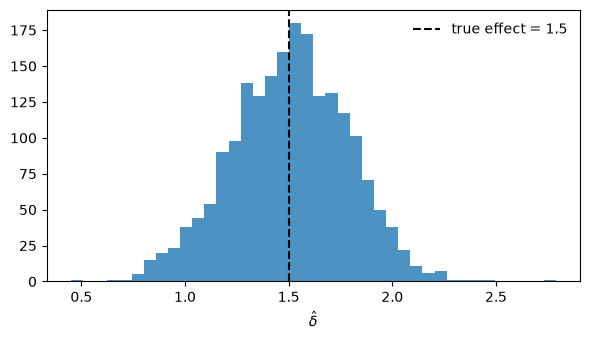

In [7]:
def simulate_did(n=200, rng=rng):
    d = pd.DataFrame({"treated": np.repeat([0, 0, 1, 1], n),
                      "post":    np.repeat([0, 1, 0, 1], n)})
    d["y"] = (alpha + beta * d.treated + gamma * d.post
              + delta * d.treated * d.post + rng.normal(0, sigma, len(d)))
    m = d.groupby(["treated", "post"]).y.mean()
    return (m[1, 1] - m[1, 0]) - (m[0, 1] - m[0, 0])

estimates = np.array([simulate_did() for _ in range(2000)])
print(f"mean = {estimates.mean():.3f}, sd = {estimates.std():.3f}")

plt.figure(figsize=(6, 3.5))
plt.hist(estimates, bins=40, alpha=0.8)
plt.axvline(delta, color="k", ls="--", label=f"true effect = {delta}")
plt.xlabel(r"$\hat\delta$"); plt.legend(frameon=False)
plt.tight_layout(); plt.show()

## Takeaways

- DiD removes both the **fixed group difference** ($\beta$) and the **common time shock** ($\gamma$).
- It identifies $\delta$ only if, absent treatment, both groups would have changed by the same amount (parallel trends).
- Try setting a different time trend for the treated group (e.g. add `0.8 * treated * post` to the outcome without the policy) and see the estimate become biased.